## 1. Environment Setup

Kiểm chứng artifact đã huấn luyện. Notebook không gọi training, không chọn lại mô hình bằng Test. Chạy từ project root hoặc bên trong project.

In [1]:
from pathlib import Path
import sys, json, platform
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'source/config.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import torch, pandas as pd
from IPython.display import display, Image
from scripts.verify_experiments import audit_runs, verify, RUNS, METRICS, FIGDIR
print('Python:', platform.python_version(), 'PyTorch:', torch.__version__, 'CUDA:', torch.cuda.is_available())
print('Verification only; no training')
def show(name): display(Image(filename=str(FIGDIR / (name + '.png'))))

Python: 3.11.15 PyTorch: 2.13.0+cu130 CUDA: False
Verification only; no training


## 2. Load Experiment Histories

Đọc năm history 30 epoch, config và checkpoint với weights_only=True. Giữ nguyên số liệu gốc.

In [2]:
histories, configs, rows = audit_runs()
print({e: {'train': len(h['train']), 'val': len(h['val'])} for e,h in histories.items()})

{'E1': {'train': 30, 'val': 30}, 'E2': {'train': 30, 'val': 30}, 'E3': {'train': 30, 'val': 30}, 'E4': {'train': 30, 'val': 30}, 'E5': {'train': 30, 'val': 30}}


## 3. Experiment Configuration Verification

Seed42, 30 epoch, batch32, Adam0.001, MLP12288→128→64→1 cố định. E1–E3 đổi initialization; E2/E4 đổi activation; E3/E5 đổi augmentation. Output initialization luôn Xavier. Augmentation chỉ Train theo config và CLI hiện tại; không có execution trace lịch sử cho từng batch.

In [3]:
display(pd.DataFrame(configs).T[['seed','epochs','batch_size','learning_rate','activation','initialization','augmentation_enabled']])
manifest = json.loads((METRICS/'m7_artifact_manifest.json').read_text())
print('Restored Validation verified for:', list(manifest['restored_validation']))
print('Historical training versions/duration were not recorded; current environment is verification only.')

Restored Validation verified for: ['E1', 'E2', 'E3', 'E4', 'E5']
Historical training versions/duration were not recorded; current environment is verification only.


,seed,epochs,batch_size,learning_rate,activation,initialization,augmentation_enabled
E1,42,30,32,0.001,relu,normal,True
E2,42,30,32,0.001,relu,xavier_normal,True
E3,42,30,32,0.001,relu,he_normal,True
E4,42,30,32,0.001,sigmoid,xavier_normal,True
E5,42,30,32,0.001,relu,he_normal,False


## 4. Validation Metrics Comparison

Mỗi hàng lấy tất cả metrics từ cùng epoch có validation loss nhỏ nhất. Train loss là thống kê online của epoch đó, không phải re-evaluation Train tại checkpoint.

,experiment,run_name,activation,initialization,augmentation,best_epoch,train_loss,validation_loss,accuracy,precision,recall,f1,tp,tn,fp,fn
0,E1,E1_relu_normal_aug,relu,normal,True,28,3.074647,2.082582,0.879121,0.917647,0.838710,0.876404,78.0,82.0,7.0,15.0
1,E2,E2_relu_xavier_aug,relu,xavier_normal,True,26,0.244340,0.255402,0.906593,0.880000,0.946237,0.911917,88.0,77.0,12.0,5.0
2,E3,E3_relu_he_aug,relu,he_normal,True,28,0.265850,0.271615,0.884615,0.846154,0.946237,0.893401,88.0,73.0,16.0,5.0
3,E4,E4_sigmoid_xavier_aug,sigmoid,xavier_normal,True,2,0.696519,0.692906,0.510989,0.510989,1.000000,0.676364,93.0,0.0,89.0,0.0
4,E5,E5_relu_he_no_aug,relu,he_normal,False,24,0.021641,0.103150,0.967033,0.948454,0.989247,0.968421,92.0,84.0,5.0,1.0


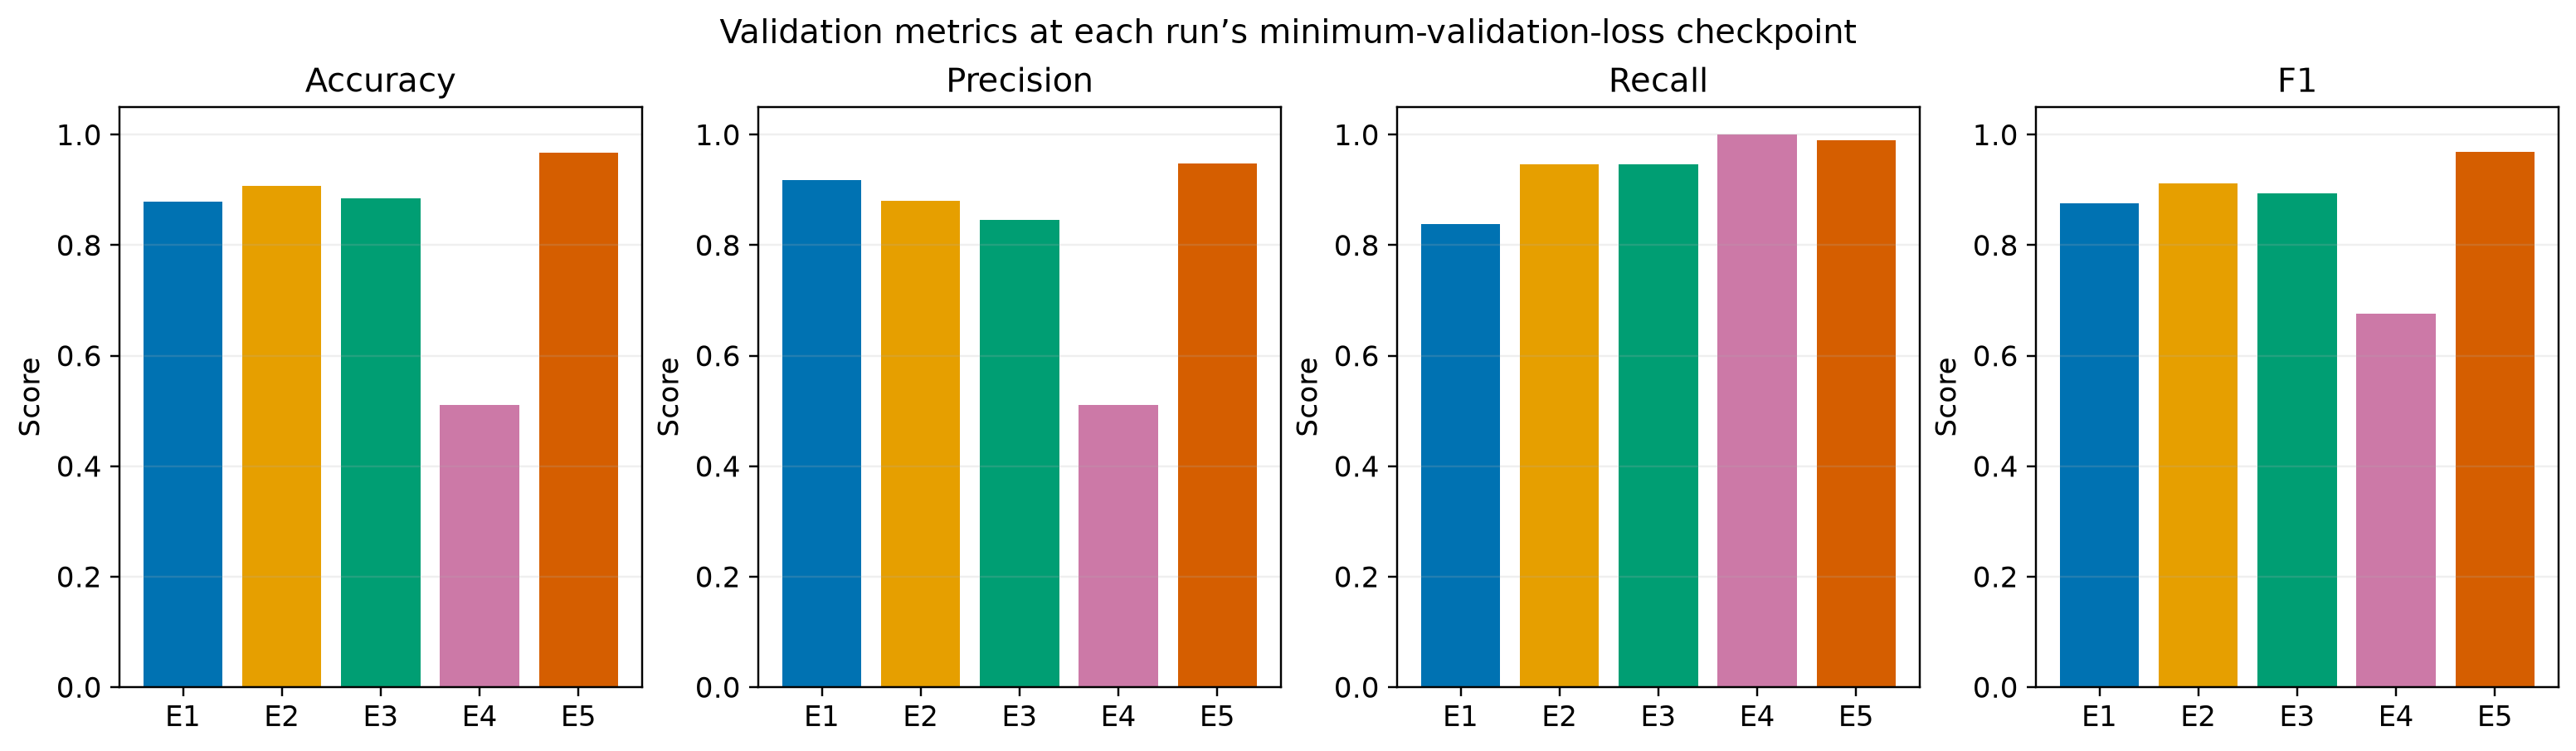

In [4]:
comparison = pd.DataFrame(rows)
display(comparison)
saved = pd.read_csv(METRICS/'experiment_comparison.csv')
pd.testing.assert_frame_equal(saved, comparison, check_dtype=False)
show('validation_metrics_comparison')

## 5. Weight Initialization Comparison

E1 Normal, E2 Xavier và E3 He có cùng ReLU/augmentation. Trục loss logarithmic giúp nhìn rõ Normal và các phương pháp scaling. Đây là hội tụ theo epoch, không phải benchmark thời gian chạy.

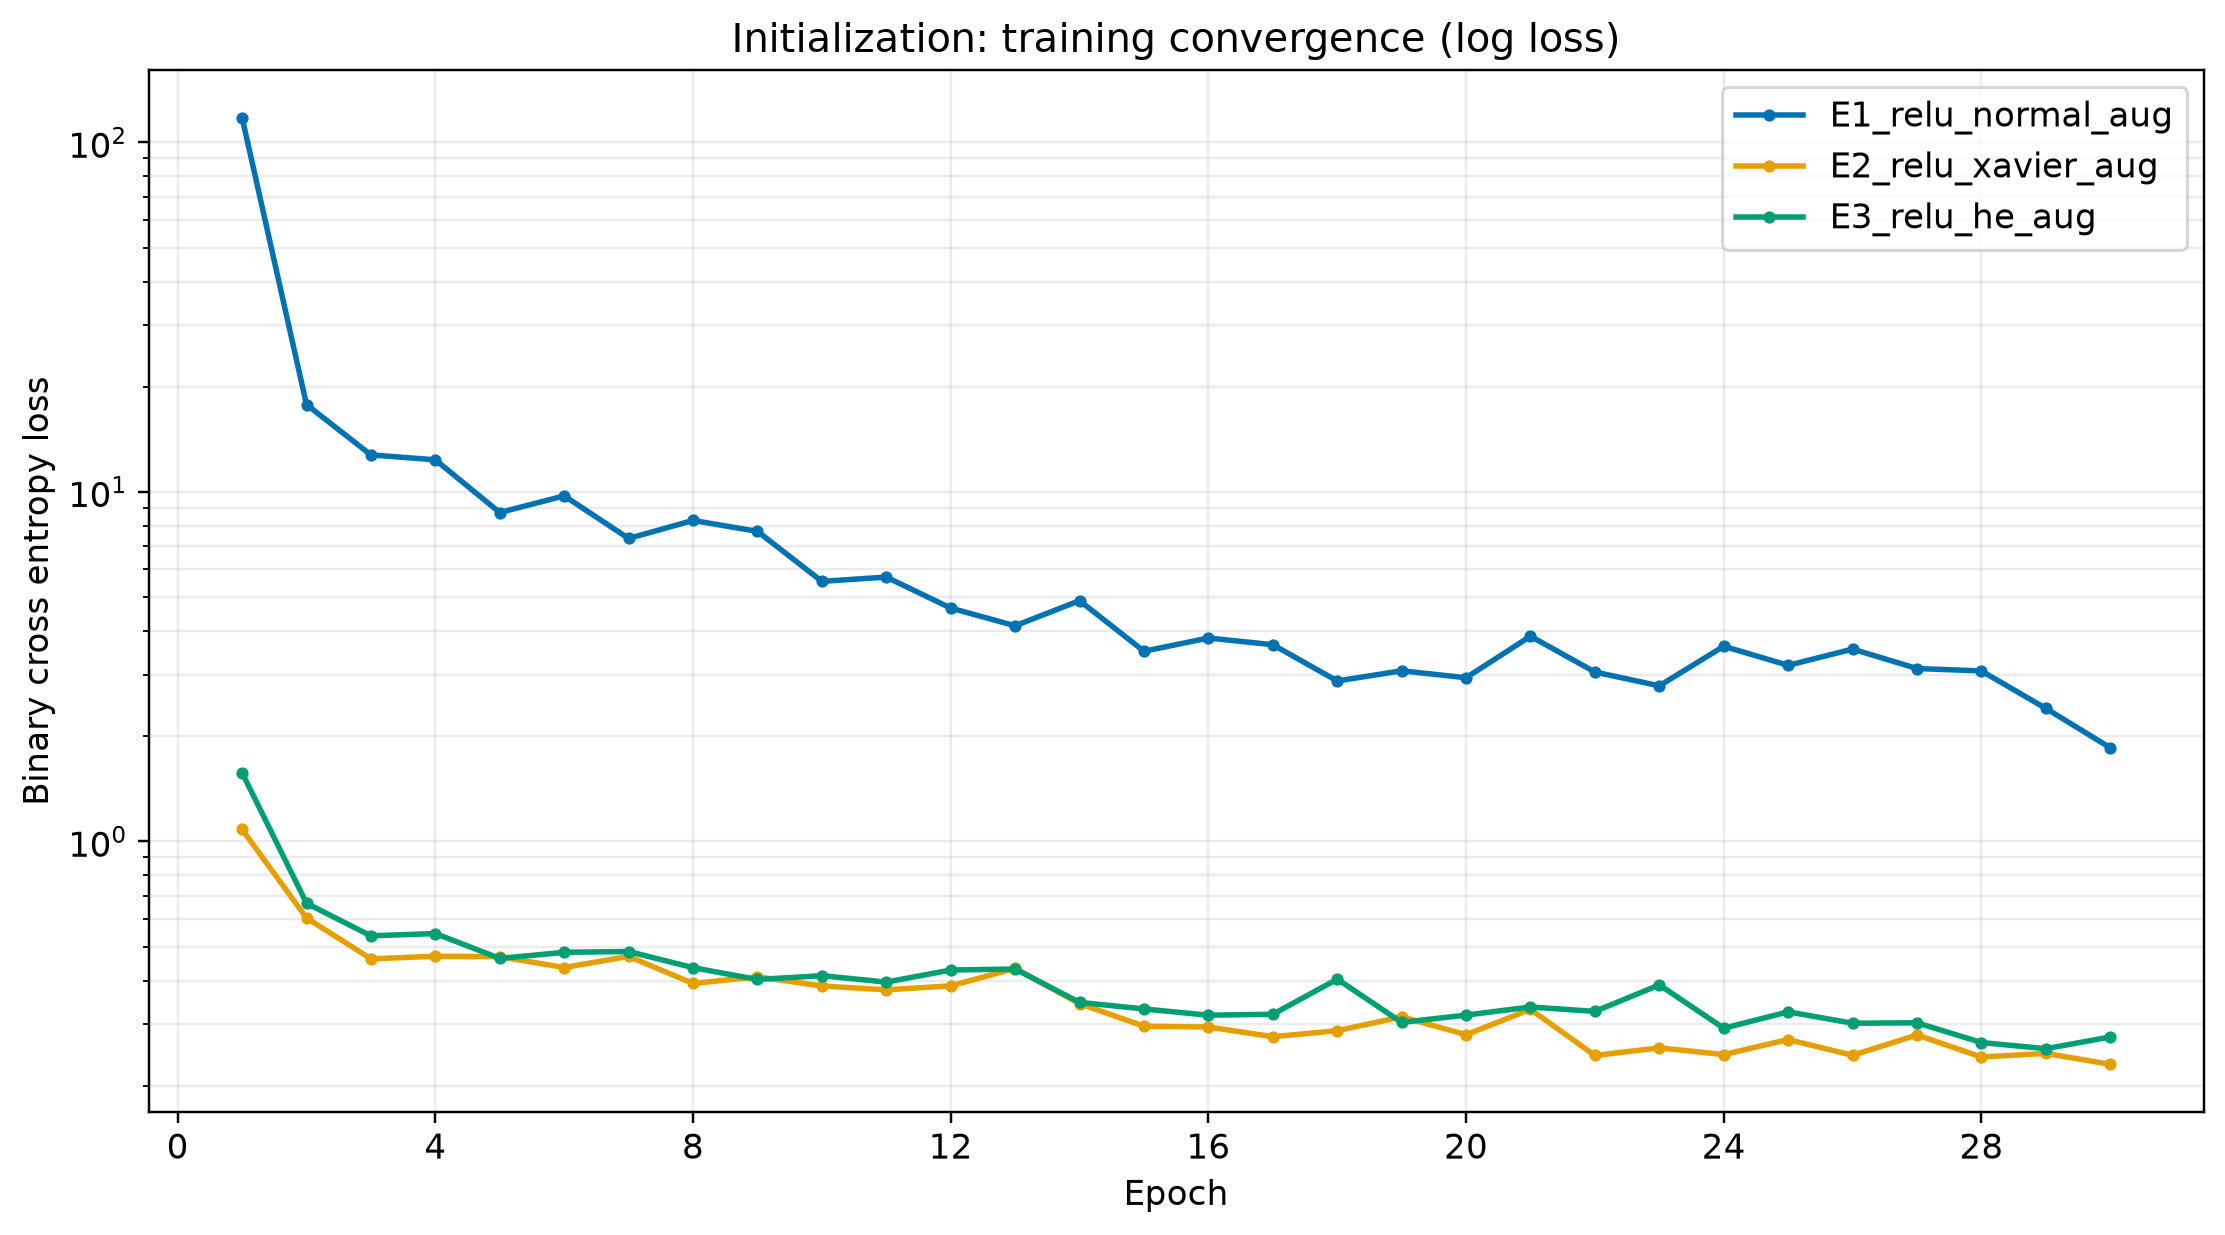

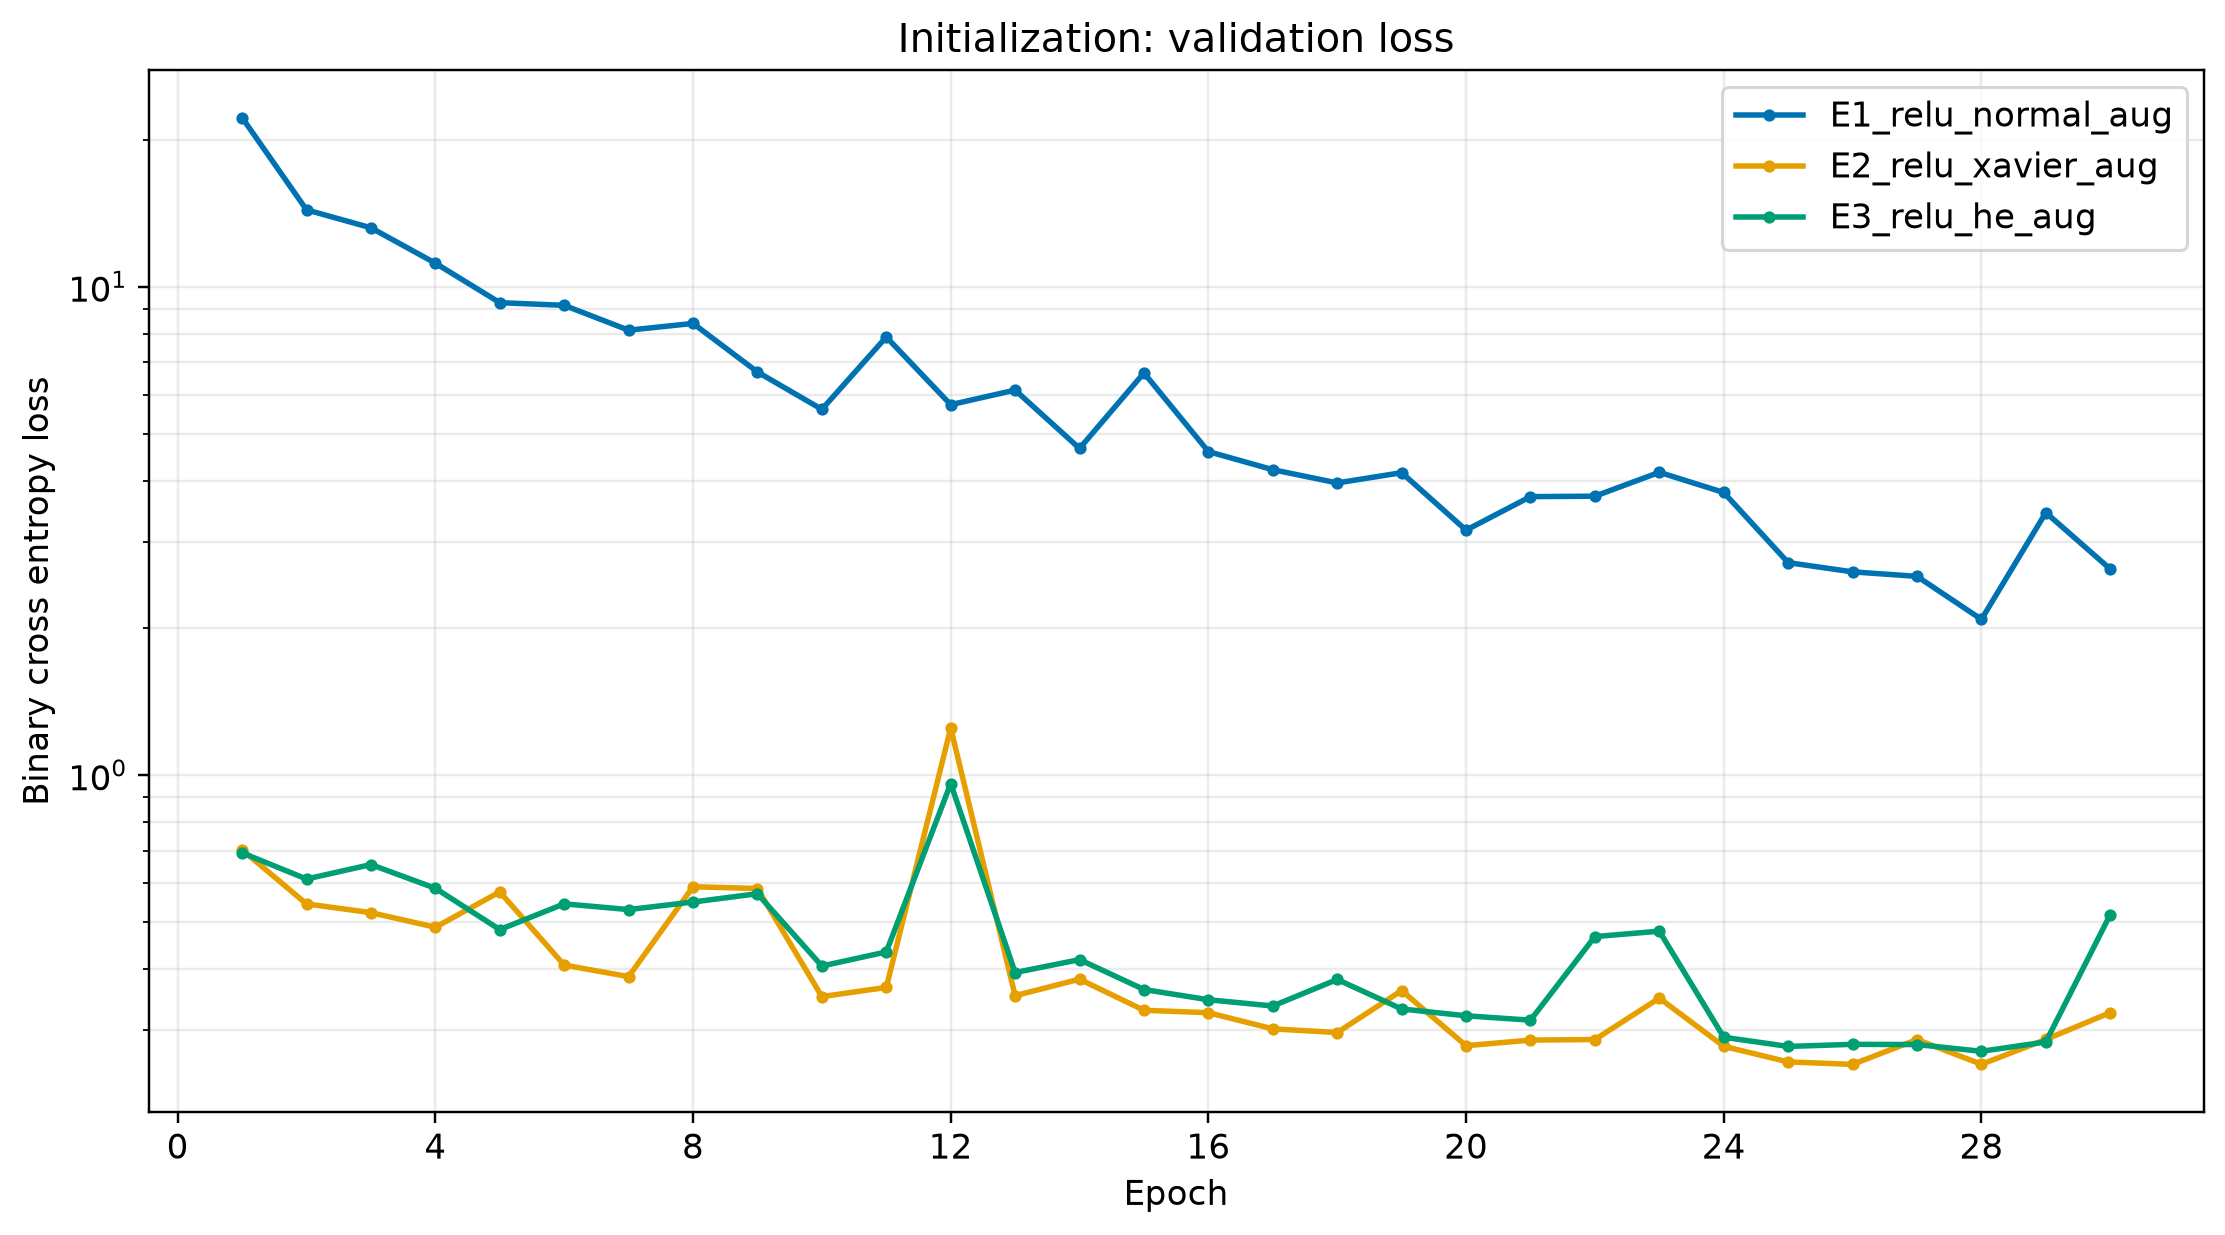

,experiment,train_loss_epoch1,train_loss_epoch30,best_val_loss
0,E1,117.735575,1.853464,2.082582
1,E2,1.081765,0.230197,0.255402
2,E3,1.572307,0.275761,0.271615


In [5]:
show('initialization_train_loss')
show('initialization_val_loss')
display(pd.DataFrame([{'experiment': e, 'train_loss_epoch1':histories[e]['train'][0]['loss'], 'train_loss_epoch30':histories[e]['train'][-1]['loss'], 'best_val_loss':histories[e]['best_val_loss']} for e in ['E1','E2','E3']]))

## 6. Activation Function Comparison

Đối chiếu ReLU/Sigmoid với Xavier và augmentation giống nhau. Không kết luận vanishing gradient từ đường loss: chưa đo gradient theo layer trong các run này.

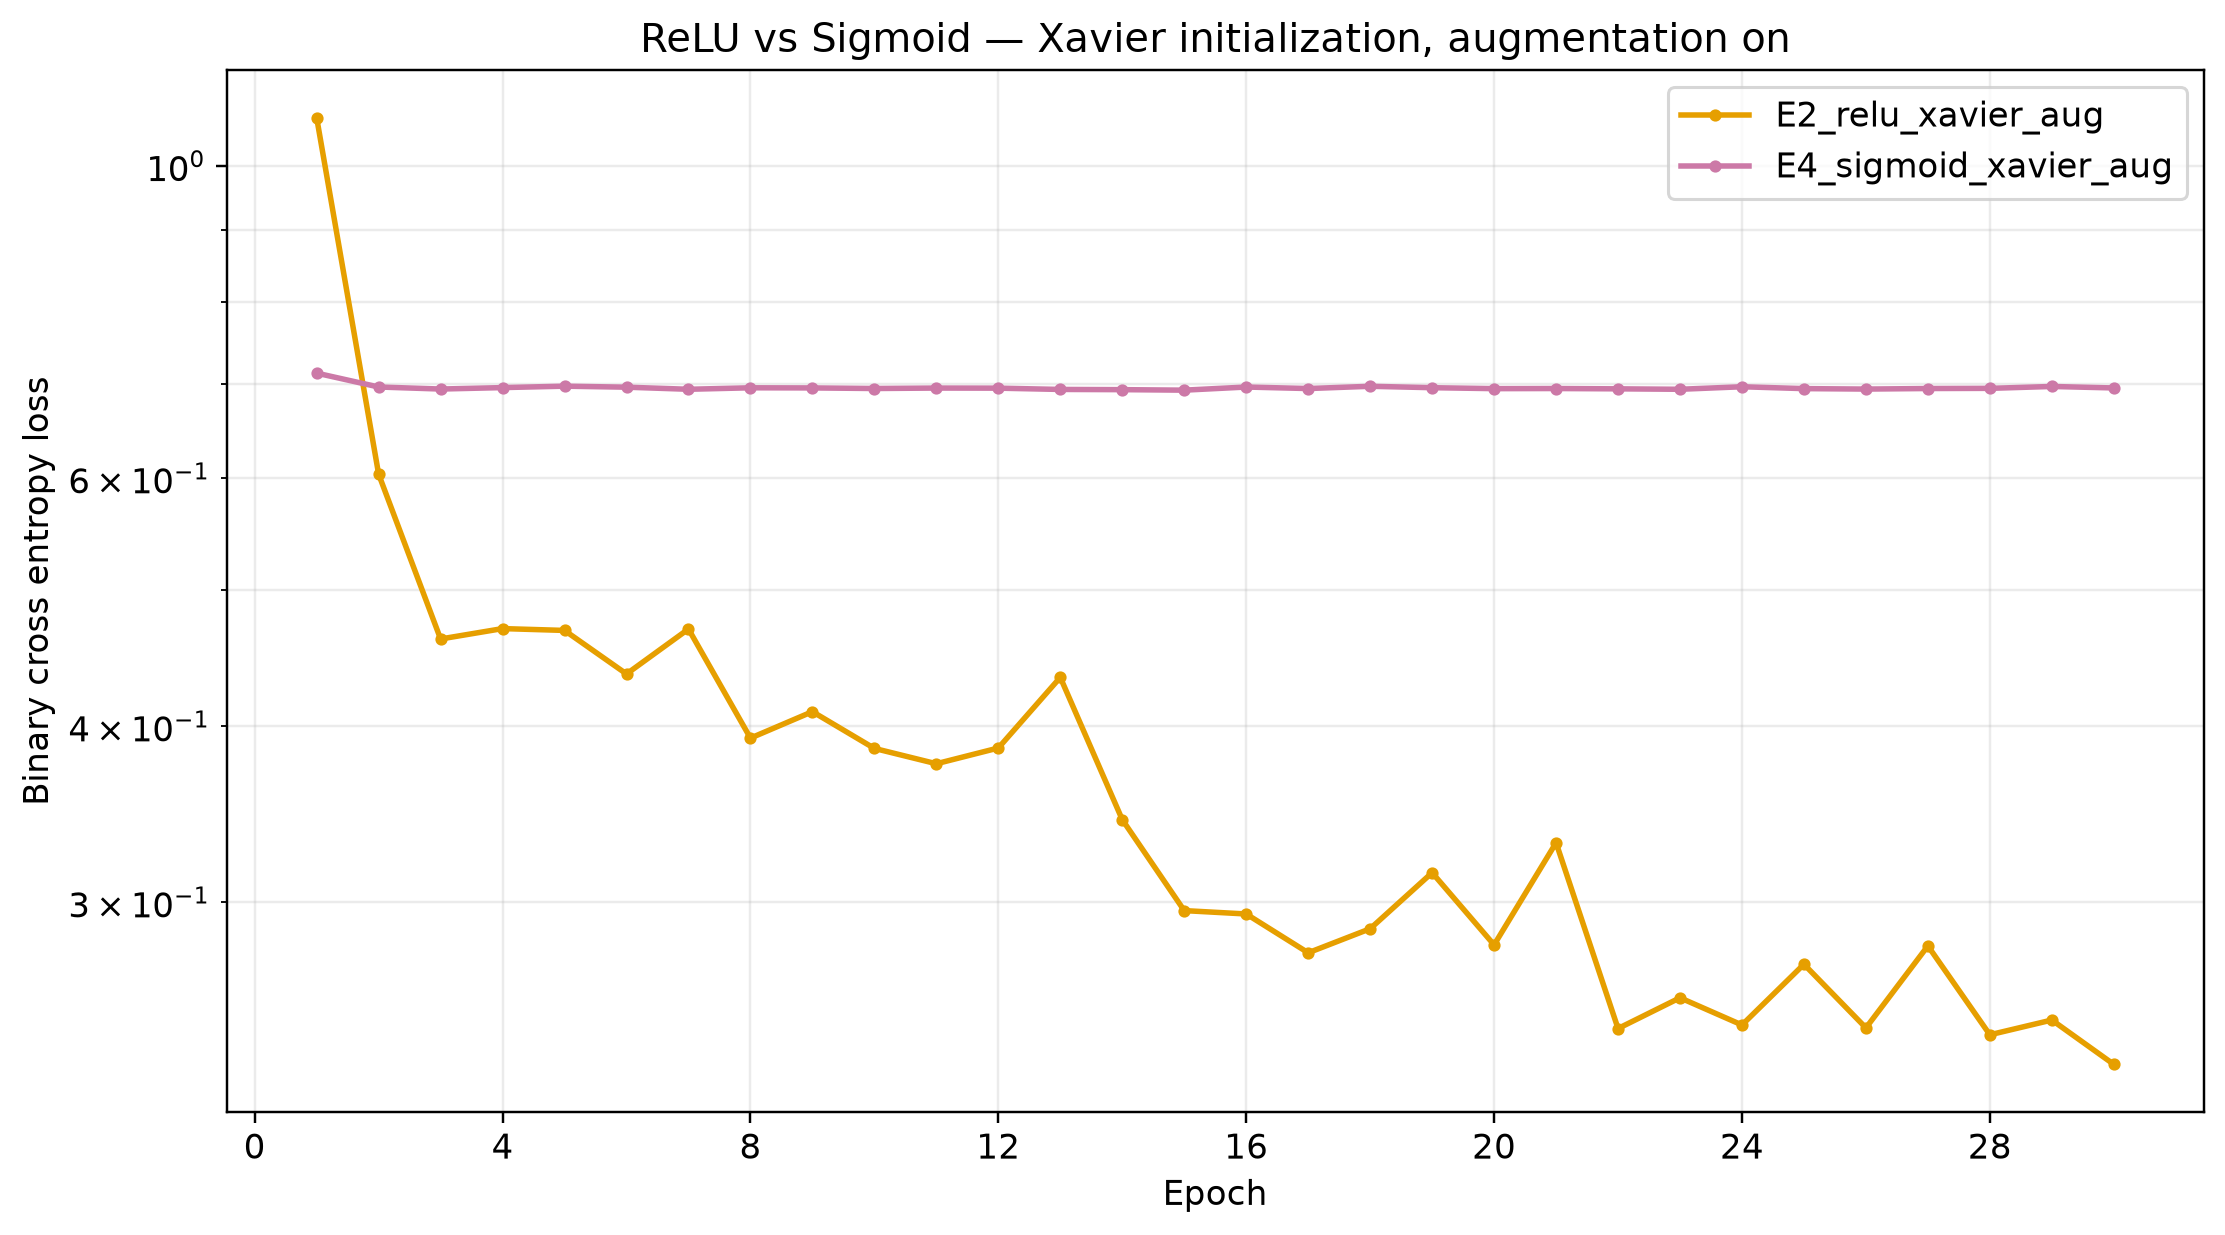

,experiment,run_name,activation,initialization,augmentation,best_epoch,train_loss,validation_loss,accuracy,precision,recall,f1,tp,tn,fp,fn
1,E2,E2_relu_xavier_aug,relu,xavier_normal,True,26,0.244340,0.255402,0.906593,0.880000,0.946237,0.911917,88.0,77.0,12.0,5.0
3,E4,E4_sigmoid_xavier_aug,sigmoid,xavier_normal,True,2,0.696519,0.692906,0.510989,0.510989,1.000000,0.676364,93.0,0.0,89.0,0.0


In [6]:
show('activation_comparison')
display(comparison[comparison.experiment.isin(['E2','E4'])])

## 7. Data Augmentation Comparison

E3/E5 cùng ReLU+He, khác augmentation. Kết quả một seed không chứng minh augmentation luôn tốt/xấu trên các dữ liệu khác.

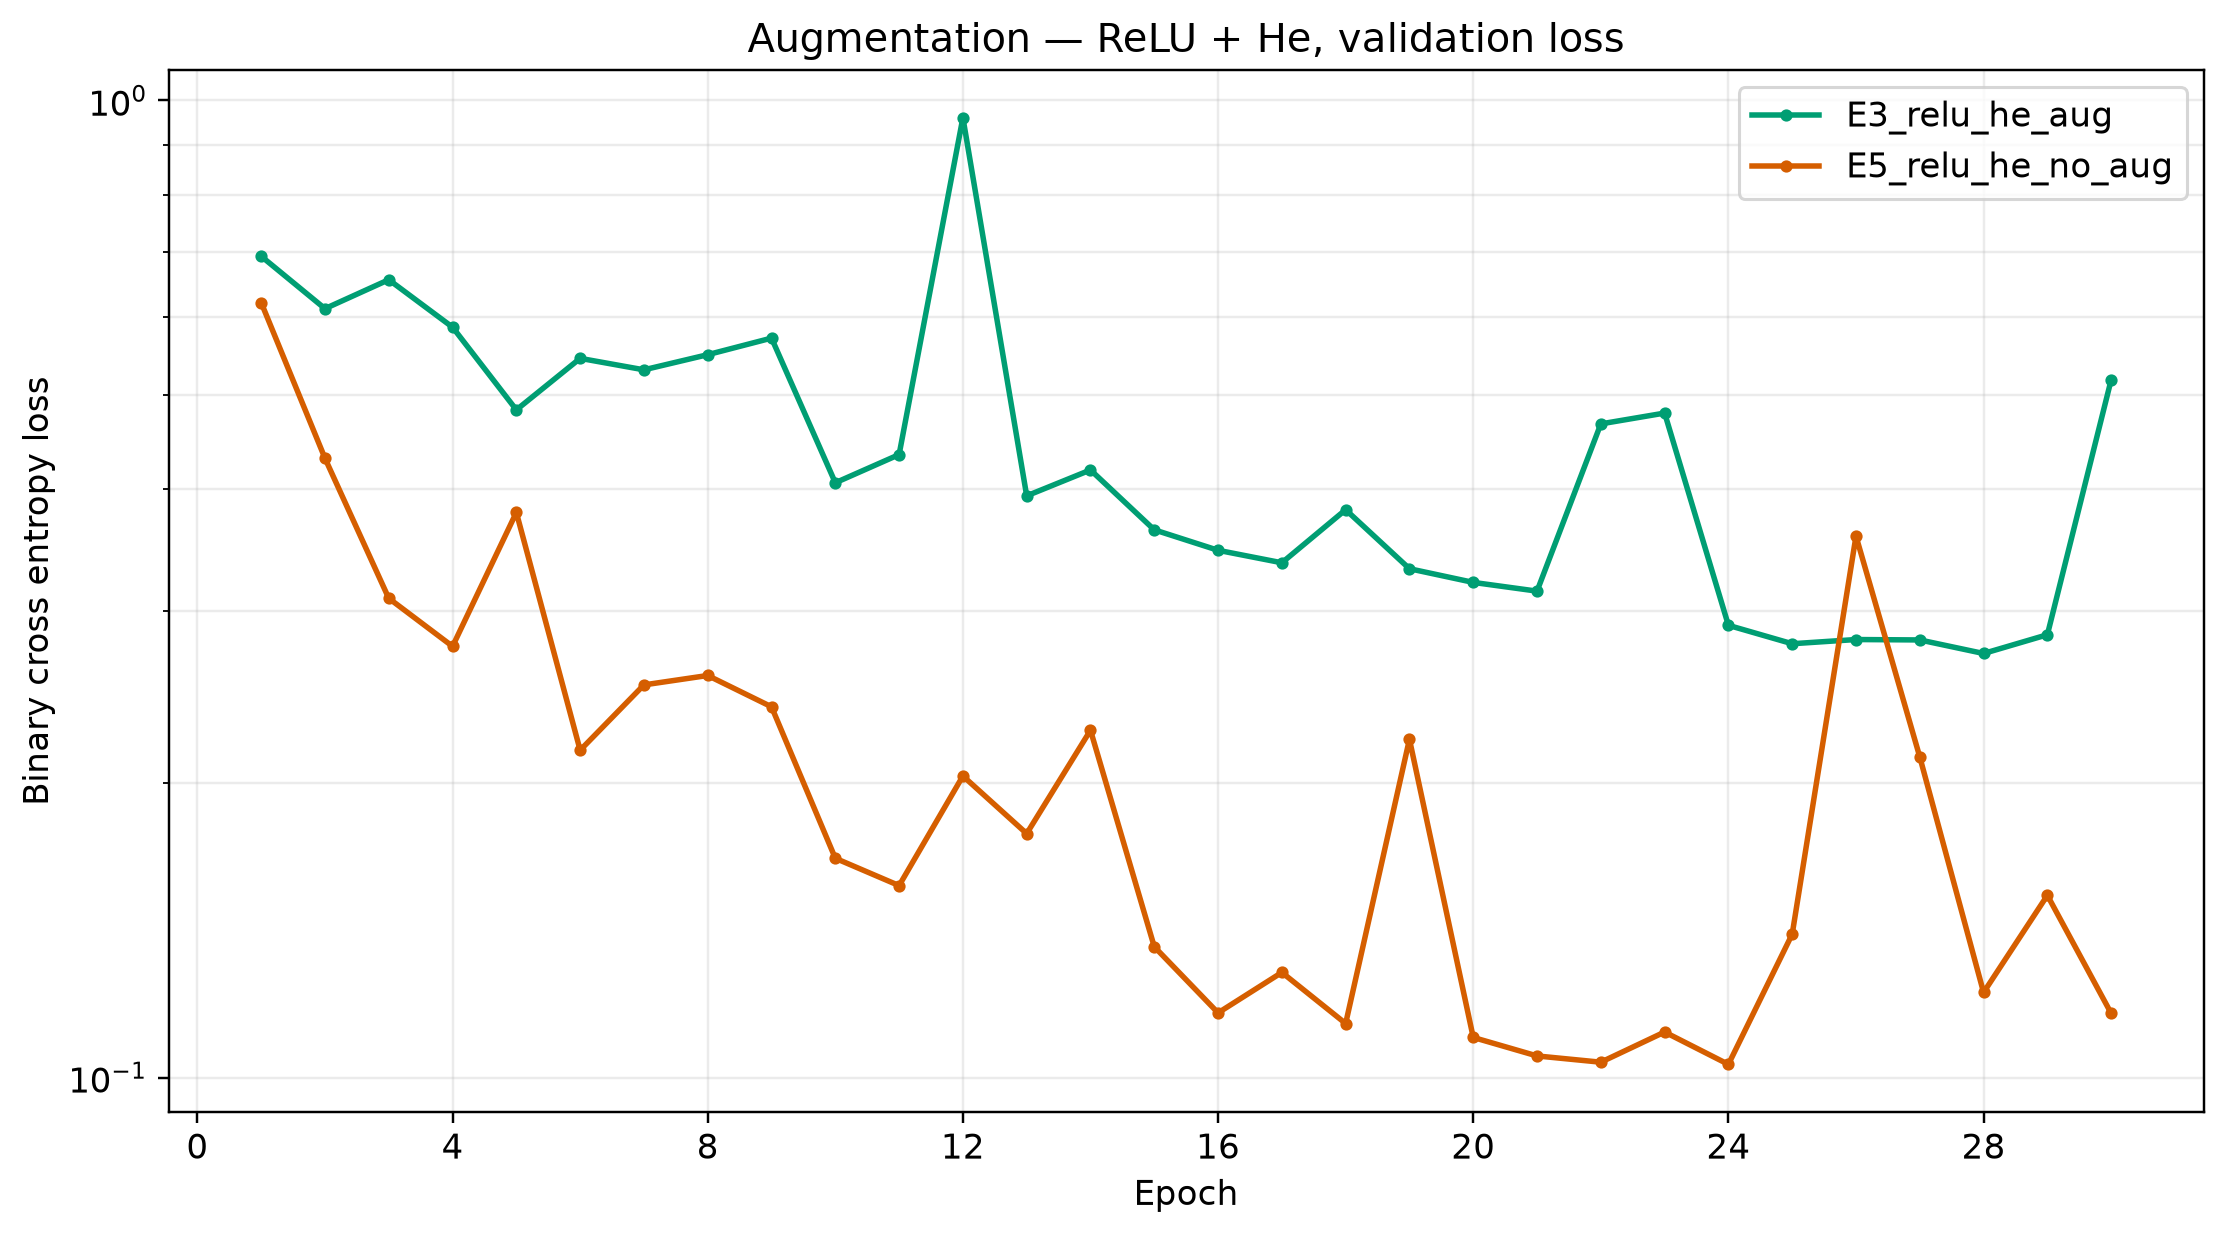

,experiment,run_name,activation,initialization,augmentation,best_epoch,train_loss,validation_loss,accuracy,precision,recall,f1,tp,tn,fp,fn
2,E3,E3_relu_he_aug,relu,he_normal,True,28,0.265850,0.271615,0.884615,0.846154,0.946237,0.893401,88.0,73.0,16.0,5.0
4,E5,E5_relu_he_no_aug,relu,he_normal,False,24,0.021641,0.103150,0.967033,0.948454,0.989247,0.968421,92.0,84.0,5.0,1.0


In [7]:
show('augmentation_effect')
display(comparison[comparison.experiment.isin(['E3','E5'])])

## 8. Best Model Selection

Chọn chỉ bằng minimum Validation Loss; Test không tham gia xếp hạng. E5 được chọn trước khi xem Test và không điều chỉnh threshold.

,experiment,run_name,activation,initialization,augmentation,best_epoch,train_loss,validation_loss,accuracy,precision,recall,f1,tp,tn,fp,fn
0,E5,E5_relu_he_no_aug,relu,he_normal,False,24,0.021641,0.10315,0.967033,0.948454,0.989247,0.968421,92.0,84.0,5.0,1.0


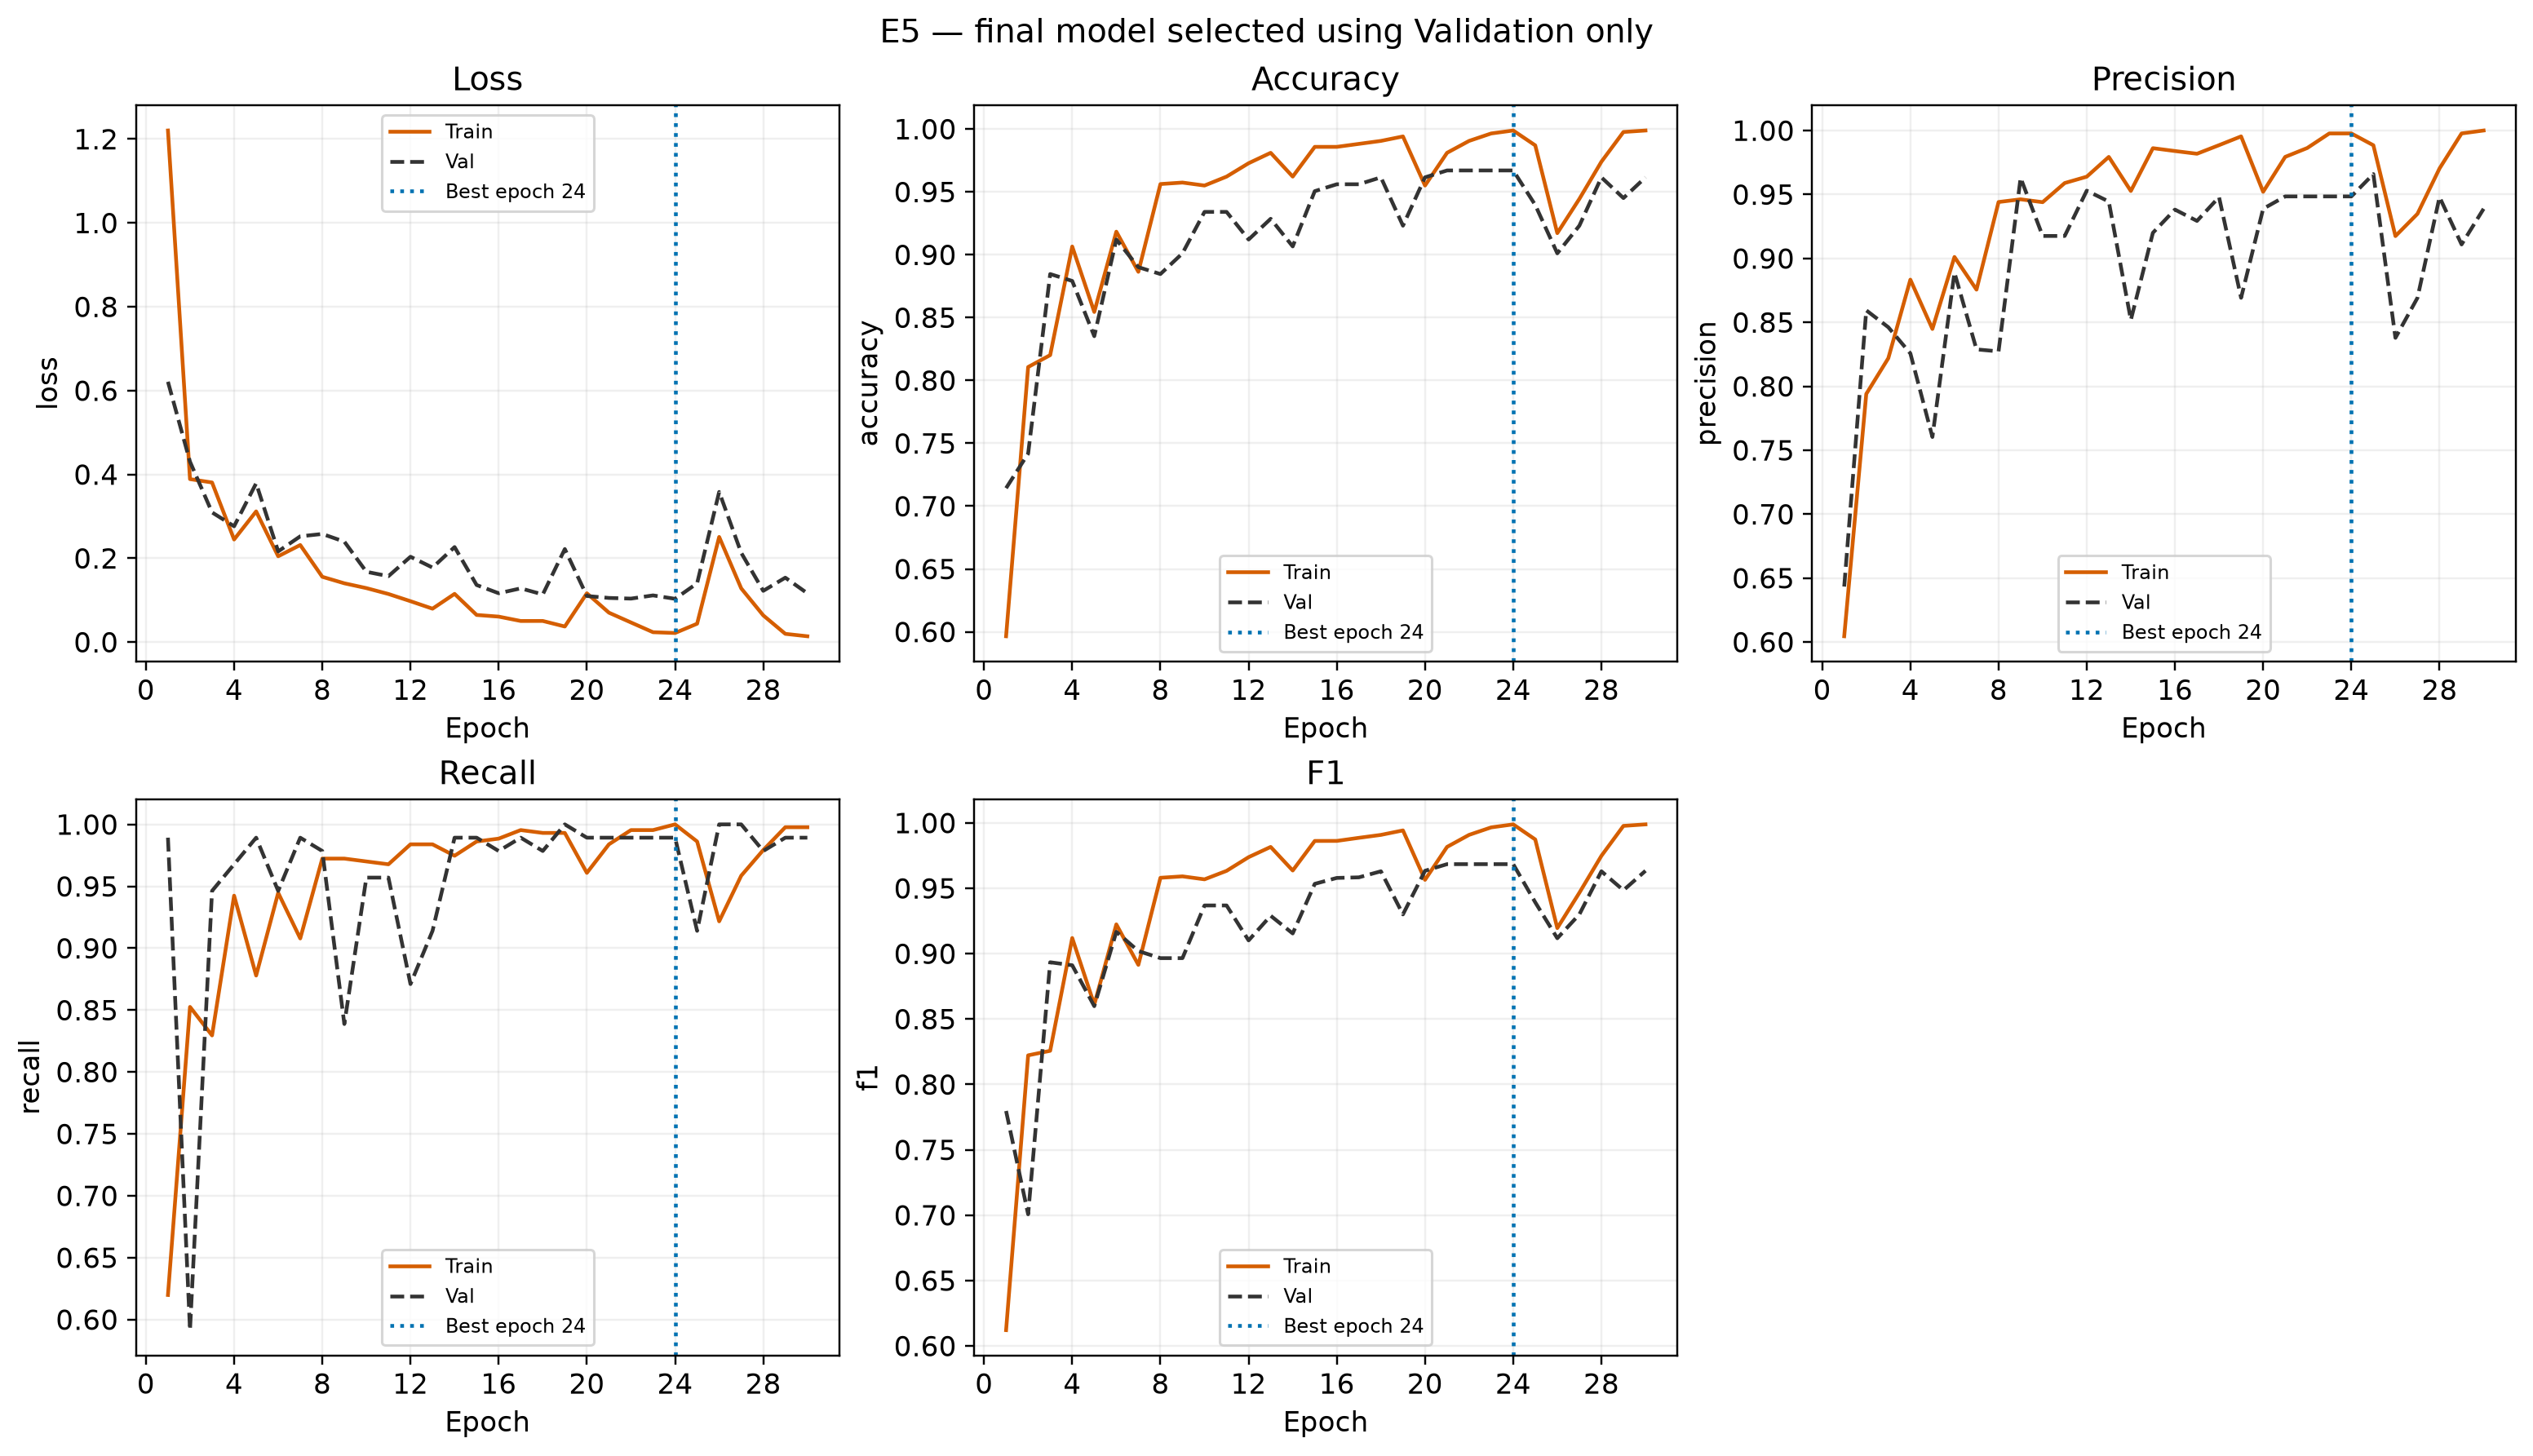

In [8]:
selected = min(rows, key=lambda r:r['validation_loss'])
assert selected['experiment']=='E5'
display(pd.DataFrame([selected]))
show('best_model_training_curves')

## 9. Final Test Evaluation

Giữ nguyên metrics Test đã lưu. Một lượt batch inference E5 trong bước chuẩn bị đã tạo CSV 256 dự đoán, đối chiếu loss/counts và thêm metadata. Notebook đọc minh chứng đã kiểm chứng, không lặp inference hoặc thay đổi weights.

In [9]:
final = json.loads((METRICS/'final_test_metrics.json').read_text())
details = pd.read_csv(METRICS/'test_prediction_details.csv')
assert final['run_name']==selected['run_name'] and final['classification_threshold']==0.5
assert len(details)==final['number_of_samples']==256
assert int((details.status=='Correct').sum())==final['tp']+final['tn']
display(pd.DataFrame([{k:v for k,v in final.items() if k!='model_configuration'}]))

,run_name,best_epoch,split,loss,accuracy,precision,recall,f1,tp,tn,fp,fn,checkpoint_path,number_of_samples,accuracy_percentage,classification_threshold
0,E5_relu_he_no_aug,24,test,0.584342,0.839844,0.8,0.90625,0.849817,116.0,99.0,29.0,12.0,results/checkpoints/E5_relu_he_no_aug.pt,256,83.984375,0.5


## 10. Confusion Matrix

Hàng là ground truth; cột là predicted. Horse0/Human1, Human là positive. Chữ trắng trên ô đậm, chữ đen trên ô sáng.

,Pred Horse,Pred Human
True Horse,99.0,29.0
True Human,12.0,116.0


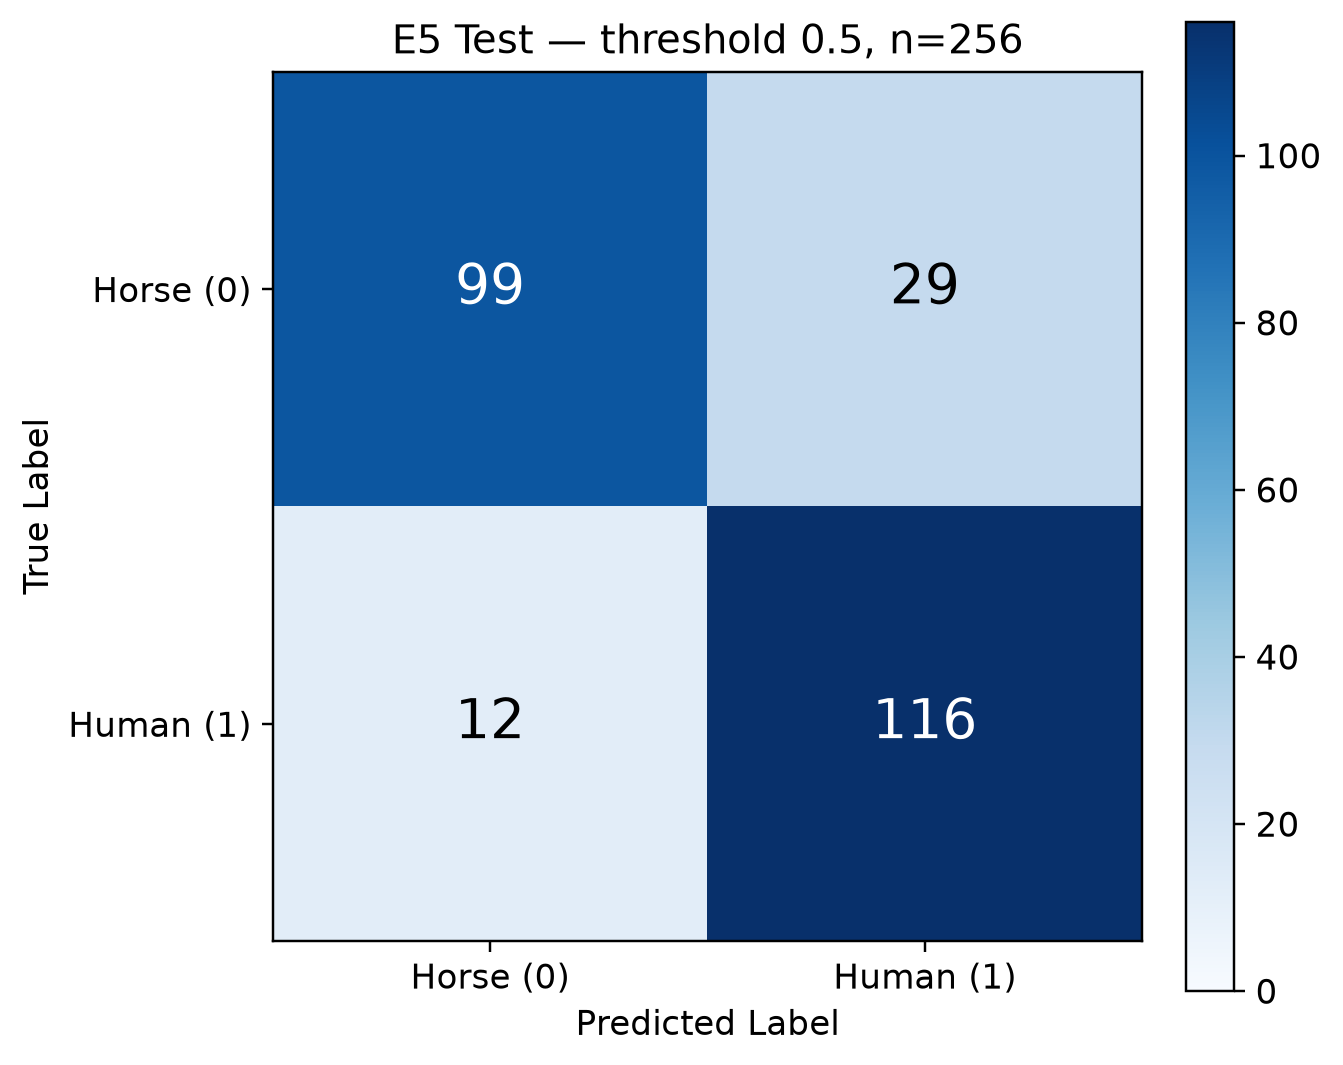

In [10]:
display(pd.DataFrame([[final['tn'],final['fp']],[final['fn'],final['tp']]],index=['True Horse','True Human'],columns=['Pred Horse','Pred Human']))
show('test_confusion_matrix')

## 11. Correct and Incorrect Predictions

Chọn bằng numpy RNG seed42, tối đa4 ảnh mỗi nhóm TN/TP/FP/FN. Ảnh gốc hiển thị, không chọn thủ công. CSV chứa toàn bộ256 mẫu chứ không chỉ16 ảnh minh họa.

Selected paths: {'TN': ['data/raw/horses/test__horse3-541.png', 'data/raw/horses/test__horse1-276.png', 'data/raw/horses/test__horse5-018.png', 'data/raw/horses/test__horse5-259.png'], 'TP': ['data/raw/humans/test__valhuman04-15.png', 'data/raw/humans/test__valhuman01-24.png', 'data/raw/humans/test__valhuman01-12.png', 'data/raw/humans/test__valhuman03-20.png'], 'FP': ['data/raw/horses/test__horse4-232.png', 'data/raw/horses/test__horse3-498.png', 'data/raw/horses/test__horse4-548.png', 'data/raw/horses/test__horse2-112.png'], 'FN': ['data/raw/humans/test__valhuman02-17.png', 'data/raw/humans/test__valhuman03-22.png', 'data/raw/humans/test__valhuman01-01.png', 'data/raw/humans/test__valhuman03-23.png']}


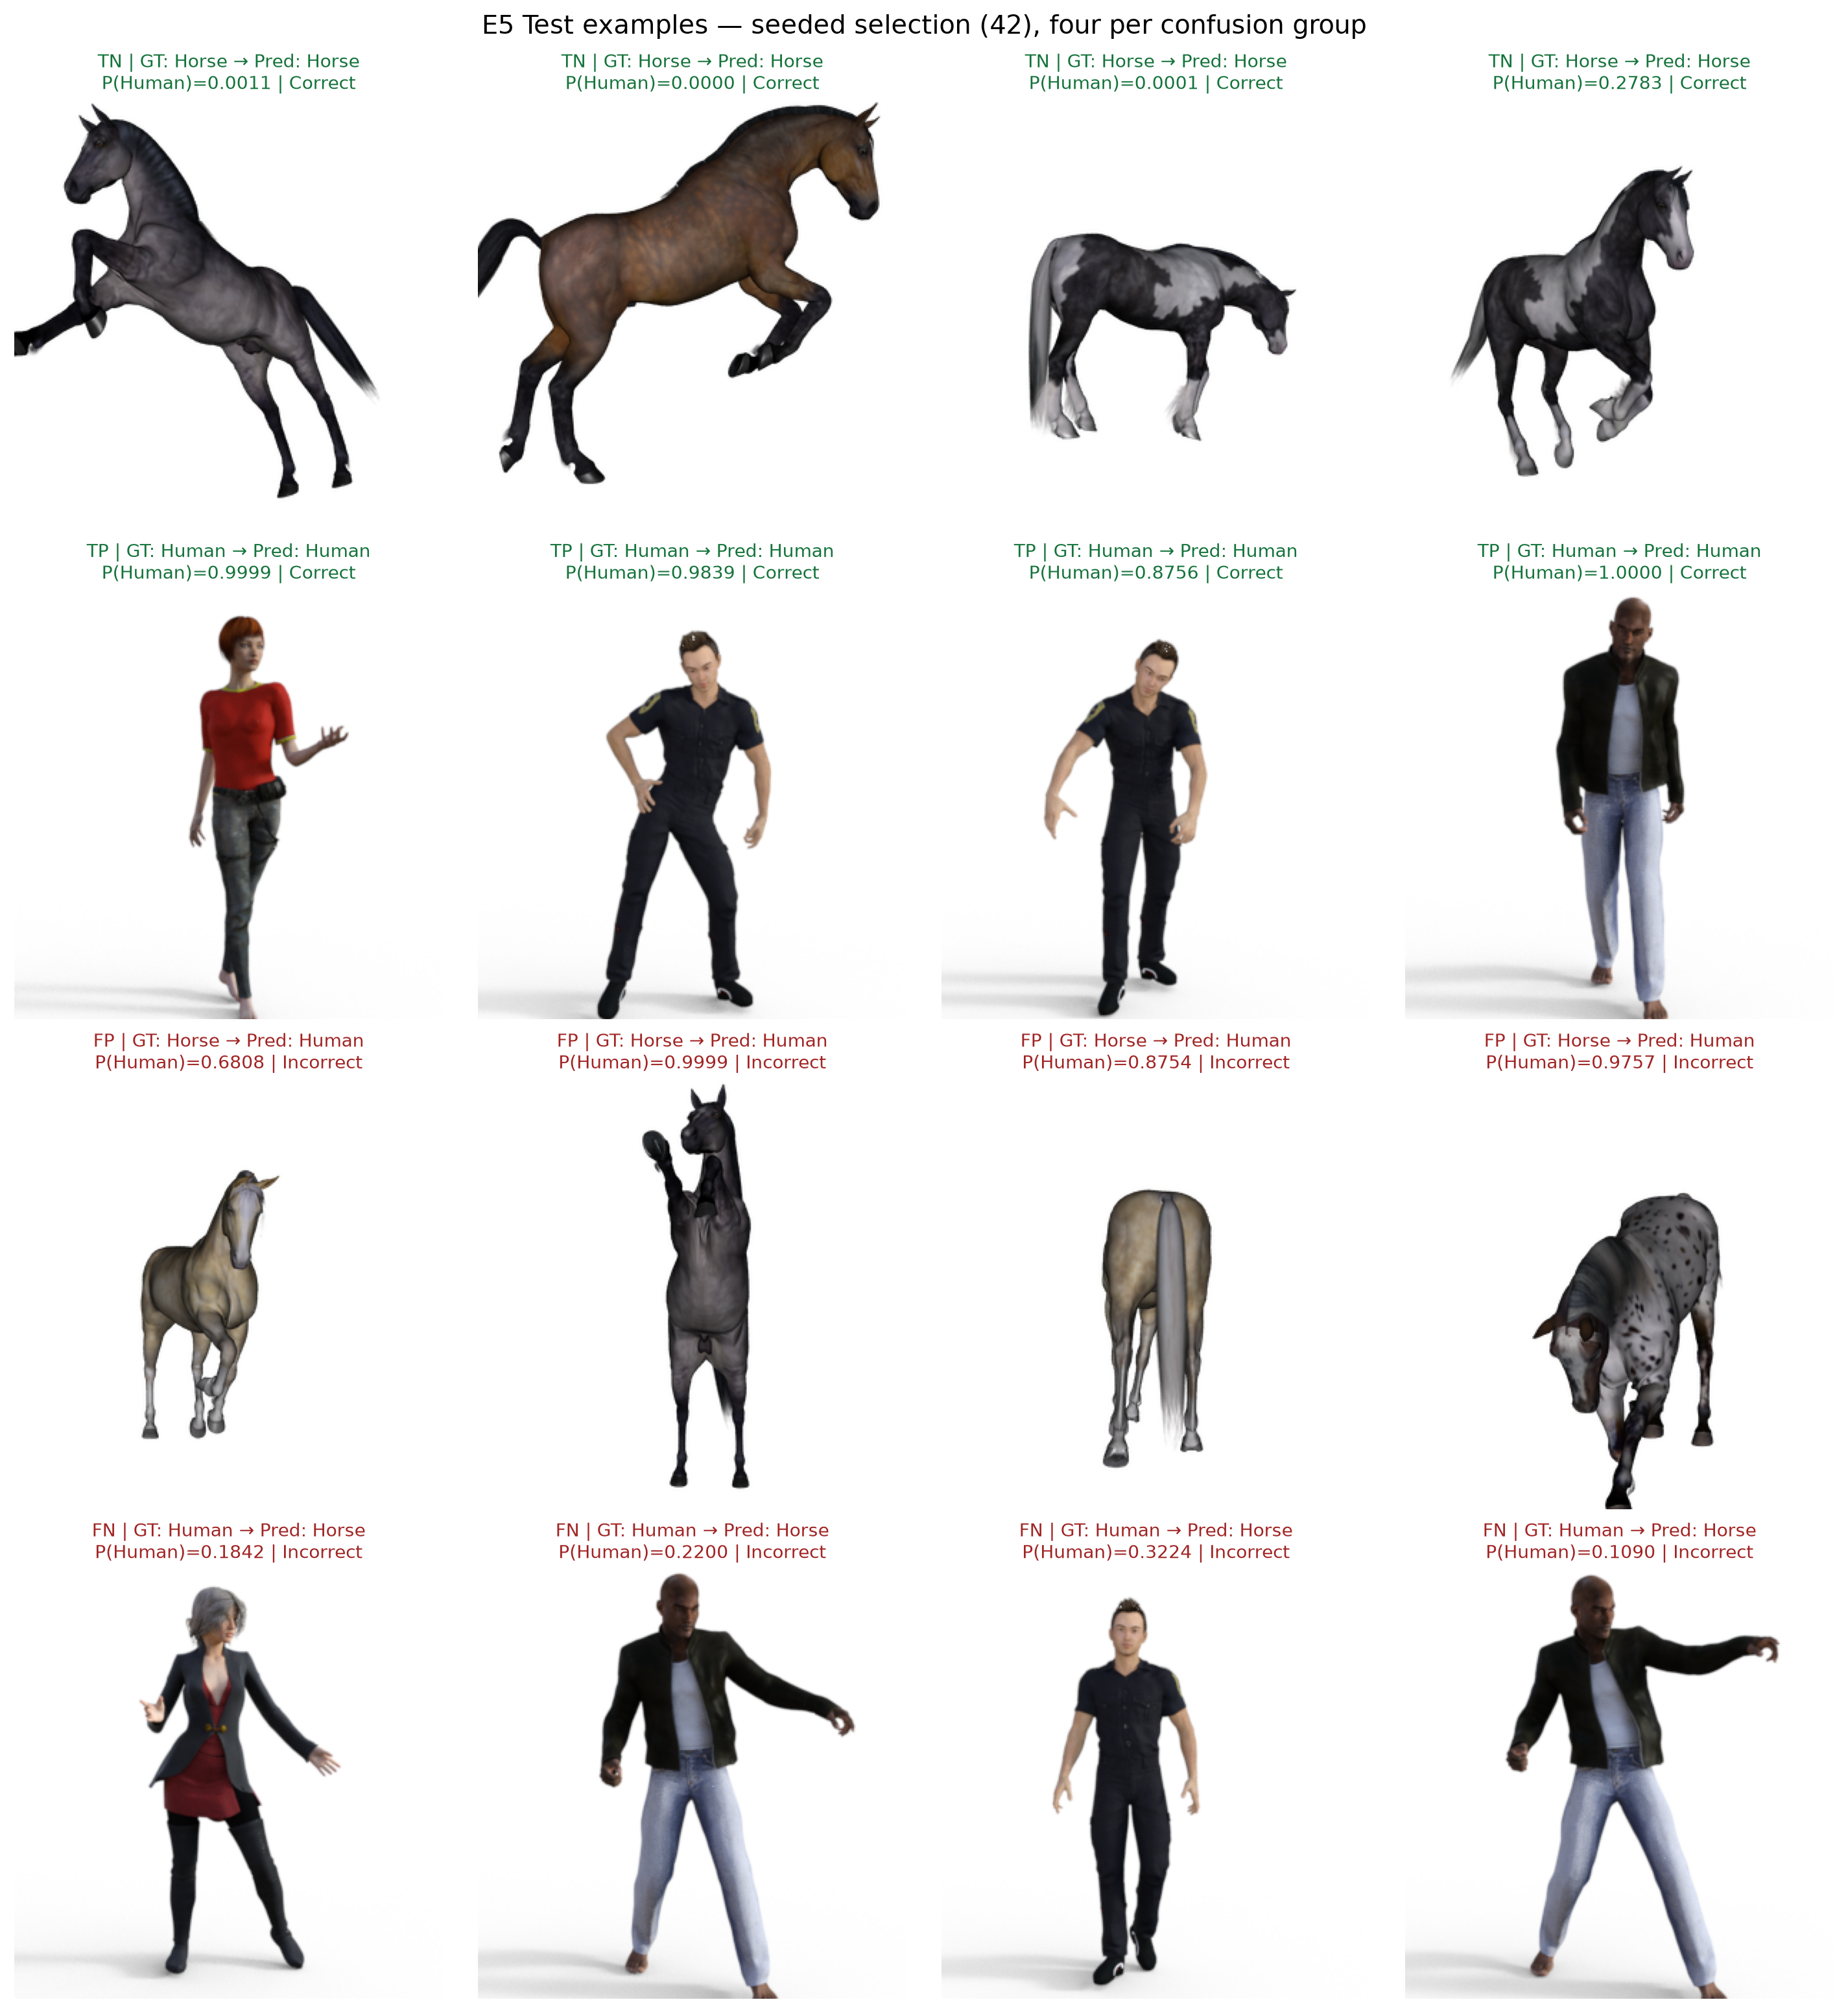

ground_truth  predicted_label
0             0                   99
              1                   29
1             0                   12
              1                  116
Name: samples, dtype: int64

In [11]:
print('Selected paths:', manifest['selected_prediction_paths'])
show('test_predictions')
display(details.groupby(['ground_truth','predicted_label']).size().rename('samples'))

## 12. Experimental Findings and Limitations

**Đã kiểm chứng:** các bảng và biểu đồ dưới đây được tính từ artifact. **Giả thuyết chưa kiểm chứng:** vanishing gradient, overfitting hoặc distribution shift có thể được nghiên cứu thêm, không được khẳng định là nguyên nhân trực tiếp. Chỉ một seed, không có confidence interval; thiếu thời gian và software versions lưu lúc training. Dữ liệu CGI và tập Test là holdout riêng. Không tối ưu theo Test; không chạy lại E1–E5.

In [12]:
e = comparison.set_index('experiment')
print(f"E5 has lowest Validation Loss: {e.loc['E5','validation_loss']:.6f}.")
print(f"E2 Xavier vs E1 Normal: {e.loc['E2','validation_loss']:.6f} vs {e.loc['E1','validation_loss']:.6f} validation loss.")
print(f"E4 predicts all 182 validation examples as Human at its best epoch: TP={e.loc['E4','tp']}, FP={e.loc['E4','fp']}.")
print(f"E5 Test accuracy: {final['accuracy_percentage']:.6f}%; Validation accuracy: {100*e.loc['E5','accuracy']:.6f}%.")
print('The observed gap alone does not identify its cause.')
checks = verify(notebook=False)
display(pd.DataFrame(checks).T)
assert all(v['status']=='PASS' for v in checks.values())

E5 has lowest Validation Loss: 0.103150.
E2 Xavier vs E1 Normal: 0.255402 vs 2.082582 validation loss.
E4 predicts all 182 validation examples as Human at its best epoch: TP=93.0, FP=89.0.
E5 Test accuracy: 83.984375%; Validation accuracy: 96.703297%.
The observed gap alone does not identify its cause.


,status
five_runs_protocol_30_epochs_metrics_best_checkpoint,PASS
comparison_same_best_epoch,PASS
final_test_metrics_confusion_consistency,PASS
all_test_prediction_details,PASS
seed42_four_confusion_groups,PASS
provenance_hashes_and_restored_validation,PASS
eight_readable_nonblank_figures_200dpi,PASS
